# Using a set of URLs, detect abnormal patterns using feature engineering. 

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

# Load dataset
df = pd.read_csv("phishing_url_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (200000, 2)
                                                 URL  Label
0  http://electrocoatingmovilparticulares.mobi/w3...      0
1                       https://www.clonefluence.com      1
2  http://wonoplata.org.ru/olb/5kmxq5zu/mrandapay...      0
3                              https://www.snohd.org      1
4                     https://www.revelrypartyco.com      1


In [2]:
def extract_features(url):
    return pd.Series({
        "url_length": len(url),
        "num_dots": url.count("."),
        "num_digits": sum(c.isdigit() for c in url),
        "num_special": len(re.findall(r"[^a-zA-Z0-9]", url)),
        "has_https": int(url.startswith("https://")),
        "has_ip": int(bool(re.search(r"\d{1,3}(\.\d{1,3}){3}", url)))
    })


# Extract features
features = df["URL"].apply(extract_features)

print(features.head())

   url_length  num_dots  num_digits  num_special  has_https  has_ip
0          76         2           7            8          0       0
1          28         2           0            5          1       0
2          81         2          10           14          0       0
3          21         2           0            5          1       0
4          30         2           0            5          1       0


In [3]:
model = IsolationForest(
    contamination=0.10,
    random_state=42
)

model.fit(features)

# Predict anomalies
features["anomaly"] = model.predict(features)

# -1 = abnormal
#  1 = normal

features["pattern"] = features["anomaly"].map({
    1: "Normal",
    -1: "Abnormal"
})

print(features["pattern"].value_counts())

pattern
Normal      180000
Abnormal     20000
Name: count, dtype: int64


In [4]:
abnormal_urls = df[features["anomaly"] == -1].copy()

print("Number of abnormal URLs:", len(abnormal_urls))

print("\nAbnormal URLs:")
print(abnormal_urls.head(20))

Number of abnormal URLs: 20000

Abnormal URLs:
                                                   URL  Label
2    http://wonoplata.org.ru/olb/5kmxq5zu/mrandapay...      0
14   http://br.fbook-47842238.safimmo.com/nextvrf.h...      0
16   http://cose.pages.dev/account/js-reporting/?cr...      0
19   http://myoffer909.000webhostapp.com/www.paypal...      0
28   https://objectstorage.sa-saopaulo-1.oracleclou...      0
46   https://anaozn.hzpmp.com/signin/?openid.pape.m...      0
53   http://signin.eday.de.ws.eayisapi.dllsigninusi...      0
55   https://www.attemplate.com/eur/081dcb9d-deea-4...      0
89   http://nationalmetalpackaging.com/wp-admin/des...      0
93   http://grotian-fork.000webhostapp.com/suntrust...      0
124  https://motoryzacja-48.pl/authorize.php?R3osl2...      0
149  https://www.claimit.otzo.com/login.php?cmd=log...      0
156  https://mp3cut2342win.ru/dfghjmhngbfvdcsx/038e...      0
157  https://www.fiveartgroup.com/Webdesign/wp-cont...      0
163  http://onlinesuppo

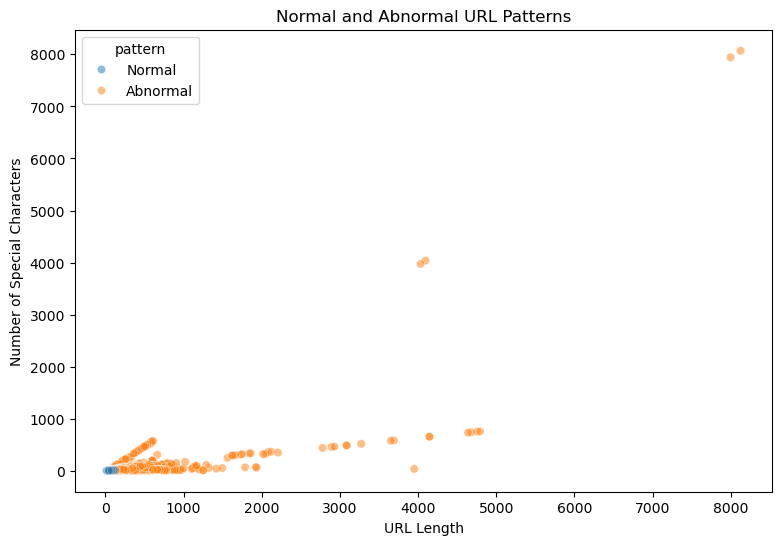

In [5]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=features,
    x="url_length",
    y="num_special",
    hue="pattern",
    alpha=0.5
)

plt.title("Normal and Abnormal URL Patterns")
plt.xlabel("URL Length")
plt.ylabel("Number of Special Characters")

plt.show()